# Murphy: LATTE through the full regional ADCP survey

Choose `SOLO_TRANSECT` below (`M1` by default). Its shallowest accepted **inner** SOLO centre supplies LATTE's initial geographic origin; a rejected SOLO Gaussian radius does not disqualify that centre. LATTE then fits **all Murphy-region ADCP observations at each measured depth**, without restricting them to either SOLO crossing or a transect time window. Each accepted LATTE inner centre seeds the next depth; rejected levels leave the previous accepted seed in place.

The overview maps the regional surface-bin ADCP vectors, both SOLO crossing tracks and their fitted surface centres. The remaining diagnostics and 2-D/3-D plots follow the SOLO notebook conventions. The survey spans 4–7 June, so spatial structure and temporal evolution can be aliased; the resulting depth profile is descriptive, not an instantaneous eddy section. “Surface” is the shallowest observed bin, 30.4 m. See [README.md](README.md) for the workflow and [transects.json](transects.json) for crossing definitions.

In [11]:
from pathlib import Path
import importlib.util
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Rectangle

candidates = [Path.cwd(), *Path.cwd().parents,
              Path.cwd() / "seacofs_eddy_tilt_analysis" / "observations"]
OBSERVATIONS_DIR = next(p for p in candidates
                        if p.name == "observations" and (p / "esp_depth_tools.py").is_file())
spec = importlib.util.spec_from_file_location("esp_depth_tools", OBSERVATIONS_DIR / "esp_depth_tools.py")
esp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(esp)

## Controls and SOLO starting centre

Edit `murphy_latte.json` for the regional footprint, fit settings and SOLO seed. Crossing windows and coordinate origins live in `transects.json`; rerun `murphy_solo.ipynb` and its export after changing them. This notebook uses every ADCP observation in the chosen region at each depth, without a crossing-time filter.


In [12]:
EDDY = "Murphy"
STUDY_DIR = OBSERVATIONS_DIR / "MNF_IN2015_V03_adcp_trawler"
CONFIG_PATH = STUDY_DIR / "murphy_latte.json"
CONFIG = json.loads(CONFIG_PATH.read_text())
TRANSECTS_PATH = STUDY_DIR / CONFIG["transects_config"]
BACKEND_PATH = Path(CONFIG["backend_path"])
DATA_PATH, transects, _ = esp.load_study(TRANSECTS_PATH, EDDY, load_adcp=False)
OUTPUT_DIR = DATA_PATH.parent / "outputs"
SOLO_RESULTS_PATH = OUTPUT_DIR / "murphy_solo_depth_fits.csv"
SOLO_TRANSECT = CONFIG["solo_transect"]
MURPHY_BOUNDS = tuple(CONFIG["bounds"])
MAP_DEPTHS = tuple(CONFIG["map_depths"])
MIN_ATTENDANCE = CONFIG["min_attendance"]
FIT = CONFIG["fit"]
HALF_WIDTH_KM = CONFIG["half_width_km"]
VELOCITY_LIMIT = CONFIG["velocity_limit"]

if SOLO_TRANSECT not in transects.index:
    raise ValueError(f"SOLO_TRANSECT must be one of {list(transects.index)}")
solo = pd.read_csv(SOLO_RESULTS_PATH)
required = {"transect_id", "depth_m", "inner_valid", "xc_lon", "yc_lat"}
if not required.issubset(solo.columns):
    raise ValueError(f"Missing SOLO output columns: {required - set(solo.columns)}")
solo["inner_valid"] = solo.inner_valid.astype(str).str.lower().eq("true")
selected = solo.loc[solo.transect_id.eq(SOLO_TRANSECT) & solo.inner_valid].sort_values("depth_m")
if selected.empty:
    raise ValueError(f"No accepted SOLO inner centre for {SOLO_TRANSECT}")
SOLO_REF = selected.iloc[0]
ORIGIN_LON_LAT = (float(SOLO_REF.xc_lon), float(SOLO_REF.yc_lat))
print(f"LATTE initial centre: {SOLO_TRANSECT} SOLO inner fit at {SOLO_REF.depth_m:g} m, "
      f"({ORIGIN_LON_LAT[0]:.5f}°E, {ORIGIN_LON_LAT[1]:.5f}°N); "
      f"Gaussian status: {SOLO_REF.status}")


LATTE initial centre: M1 SOLO inner fit at 30.4 m, (154.85018°E, -28.61157°N); Gaussian status: ok


## Surface ADCP overview

Grey arrows sample the full Murphy-region survey at the shallowest ADCP bin. Coloured lines show the two short SOLO crossings; crosses mark their shallowest accepted inner centres. The red frame is the regional selection. The vectors were sampled over several days.

selected_rows                                              39422
used_rows                                                  39422
unique_times                                                 876
start_utc                              2015-06-04 00:01:22+00:00
end_utc                                2015-06-07 01:56:23+00:00
depth_range_m                                      [30.4, 814.4]
missing_avg_qc                                             39422
zero_attendance_rows                                       19420
min_attendance                                              None
origin_lon_lat          (154.85018371042003, -28.61156558451823)
bounds_lon_lat                      (153.5, 156.0, -29.8, -27.6)
Name: LATTE selection audit, dtype: object

path                 /home/z5297792/ESP_zonodo/functions.py
sha256    10208a788eea38e9451edc3a2f31aaa351f043e3cb6ed5...
Name: ESP backend, dtype: object

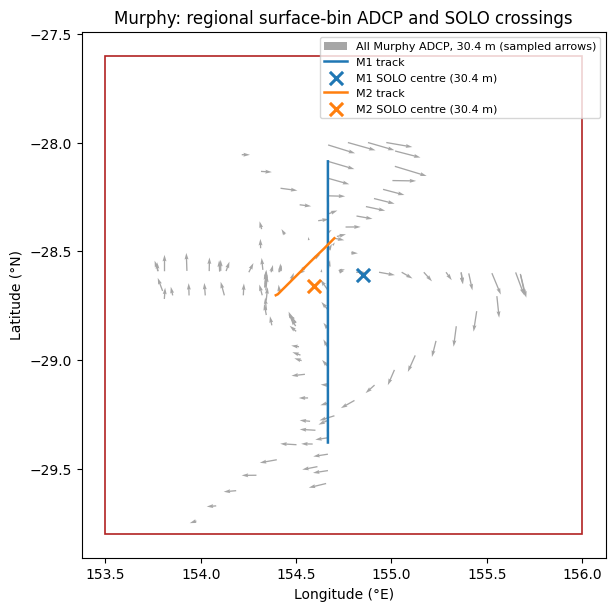

In [13]:
backend, backend_info = esp.load_backend(BACKEND_PATH)
data, coverage, audit = esp.load_observations(
    DATA_PATH, None, None, ORIGIN_LON_LAT,
    min_attendance=MIN_ATTENDANCE, bounds=MURPHY_BOUNDS)
display(pd.Series(audit, name="LATTE selection audit"))
display(pd.Series(backend_info, name="ESP backend"))

esp.plot_regional_track(
    data, transects, solo, MURPHY_BOUNDS,
    title="Murphy: regional surface-bin ADCP and SOLO crossings",
    colours=("tab:blue", "tab:orange"), figsize=(8, 6), surface_tracks=True,
    velocity_label="All Murphy ADCP", track_width=1.8,
    centre_size=90, centre_width=2.2, legend_kwargs=dict(fontsize=8, loc="best"))
plt.show()

## LATTE fits from shallow to deep

Every depth uses the full regional sample at that depth. Accepted inner fits update the centre and ellipse used to select the next core, even if the Gaussian outer stage fails. The table retains failed levels and separates centre support from reconstruction support.

LATTE: 48/50 accepted inner fits; 48/50 accepted Gaussian reconstructions.
status
collinear_latte_sampling     1
invalid_ellipse              1
ok                          48
Centre offsets reference the shallowest accepted fit: 30.4 m.
Reconstructed measured levels: 30.4–798.4 m (gaps retained).
The ADCP sampling limit is not an estimate of the eddy bottom. R² is in-sample.


,depth_m,status,n_obs,n_core,inner_valid,valid,core_spread_ratio,inner_R2,alpha,Rc_m,vector_R2
0,30.4,ok,875,425,True,True,0.8410,0.7415,1.1542,129652.9657,0.7735
1,46.4,ok,861,444,True,True,0.8491,0.7201,1.1321,141049.5012,0.7917
2,62.4,ok,848,441,True,True,0.8437,0.7490,1.1026,155800.9300,0.8119
3,78.4,ok,842,440,True,True,0.8418,0.7205,1.1122,165882.6345,0.8166
4,94.4,ok,841,442,True,True,0.8270,0.6844,1.1345,163731.3124,0.8065
5,110.4,ok,839,443,True,True,0.7949,0.6620,1.1470,157469.6466,0.7984
6,126.4,ok,838,449,True,True,0.7636,0.6747,1.2160,128316.0768,0.7822
7,142.4,ok,835,446,True,True,0.7594,0.6891,1.2290,122333.4676,0.7826
8,158.4,ok,833,445,True,True,0.7467,0.6912,1.2314,122157.3817,0.7853
9,174.4,ok,832,446,True,True,0.7334,0.6975,1.2395,123817.9049,0.7895


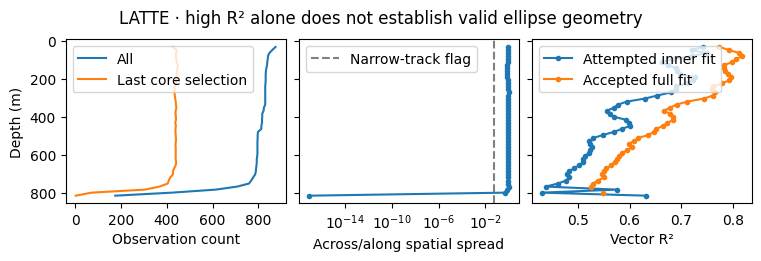

In [14]:
results, samples = esp.fit_depths(
    data, backend, "LATTE", depth_levels=coverage.index, **FIT)
esp.report(results)
columns = ["depth_m", "status", "n_obs", "n_core", "inner_valid", "valid",
           "core_spread_ratio", "inner_R2", "alpha", "Rc_m", "vector_R2"]
with pd.option_context("display.max_rows", 60):
    display(results[columns].round(4))
esp.plot_diagnostics(results)
plt.show()

## Centre trajectory and reconstruction

Offsets are relative to LATTE's shallowest accepted centre; the chosen SOLO centre is only its initial seed. The horizontal maps, 3-D view and fixed zonal/meridional sections use the same helper and scales as the SOLO notebook. Reconstructed flow away from sampled points is model-based extrapolation, and the deepest ADCP bin does not define the eddy bottom.

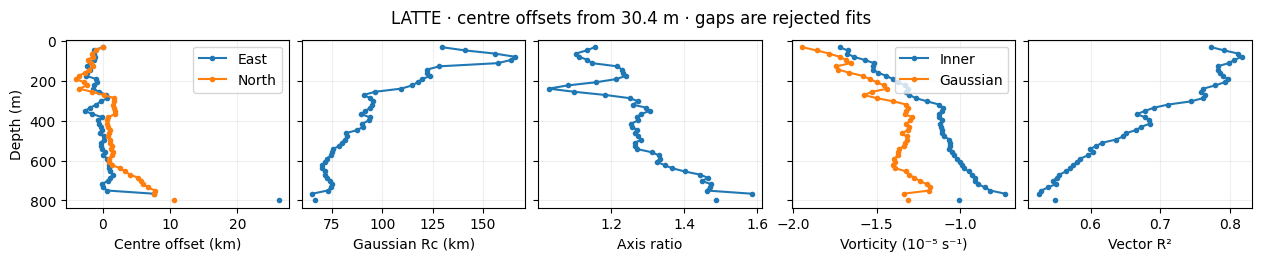

In [15]:
esp.plot_profiles(results)
plt.show()

1.27 km mean spacing


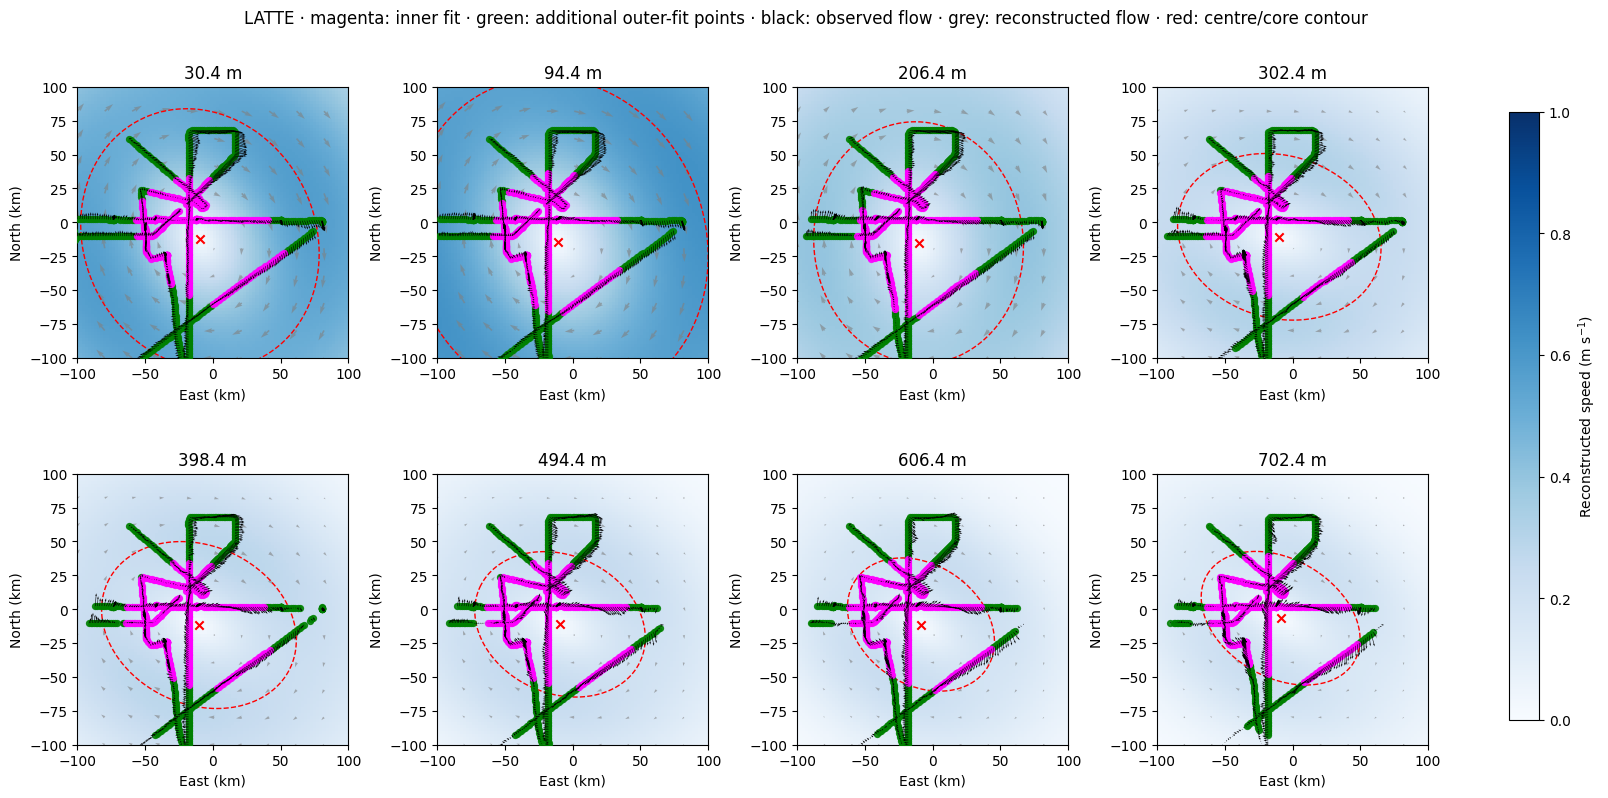

In [16]:
esp.plot_maps(results, samples, backend, depths=MAP_DEPTHS,
              half_width_km=HALF_WIDTH_KM, speed_max=VELOCITY_LIMIT)
plt.show()

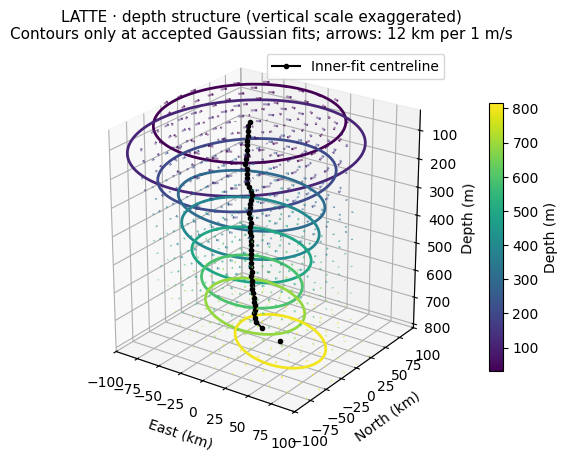

In [17]:
esp.plot_3d(results, backend, half_width_km=HALF_WIDTH_KM)
plt.show()

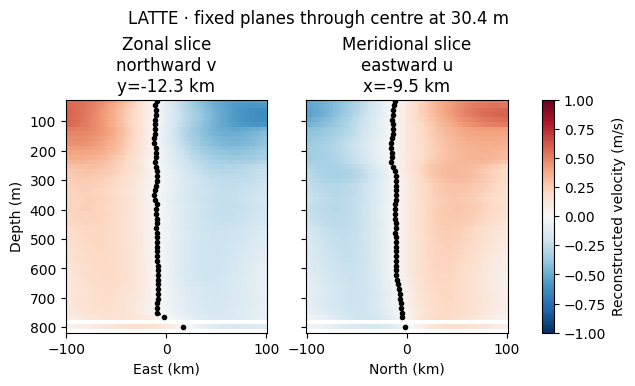

In [18]:
esp.plot_sections(results, backend, half_width_km=HALF_WIDTH_KM,
                  speed_max=VELOCITY_LIMIT)
plt.show()

## Export to scratch

The CSV includes accepted and rejected depths. The companion JSON records the full regional selection, SOLO seed, fit settings and backend fingerprint. Both stay beside this voyage's input CSV under `outputs/`.

In [19]:
SAVE_RESULTS = CONFIG["save_results"]
if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    results.to_csv(OUTPUT_DIR / "murphy_latte_depth_fits.csv", index=False)
    provenance = dict(eddy=EDDY, method="LATTE", data_path=str(DATA_PATH),
                      config_path=str(CONFIG_PATH), transects_config_path=str(TRANSECTS_PATH), backend=backend_info,
                      solo_results_path=str(SOLO_RESULTS_PATH),
                      solo_transect=SOLO_TRANSECT,
                      solo_surface_fit=SOLO_REF.to_dict(),
                      selection=audit, fit_settings=FIT)
    (OUTPUT_DIR / "murphy_latte_provenance.json").write_text(
        json.dumps(provenance, indent=2, default=str))
    print(f"Saved LATTE results to {OUTPUT_DIR}")

Saved LATTE results to /srv/scratch/z5297792/tilt_observation_data/MNF_IN2015_V03_adcp_trawler/outputs


## Along-track bin sensitivity

Set `along_track_bin_km` in `murphy_latte.json` to the widths to compare. The same binning and four-panel comparison as the SOLO notebooks are used, with LATTE fits and this notebook’s original fit settings. Each occupied projected along-track cell contributes one mean position and east/north velocity vector at each measured depth. All centre offsets reference the original shallowest accepted inner centre; `Rc` requires an accepted Gaussian fit and vorticity requires an accepted inner fit. This comparison does not change exported fits.

This uses the existing full regional selection, without a time filter. Bins project onto its shallowest-bin principal axis, so different ship passes at the same projected distance can be averaged together, including across sampling times. Interpret this as a regional sampling sensitivity rather than regular spacing along a single crossing.


,vectors,inner_depths,Rc_depths
bin,,,
Original,39422,48,48
2 km,5642,26,24
5 km,2288,19,17
10 km,1147,21,21
20 km,600,23,21


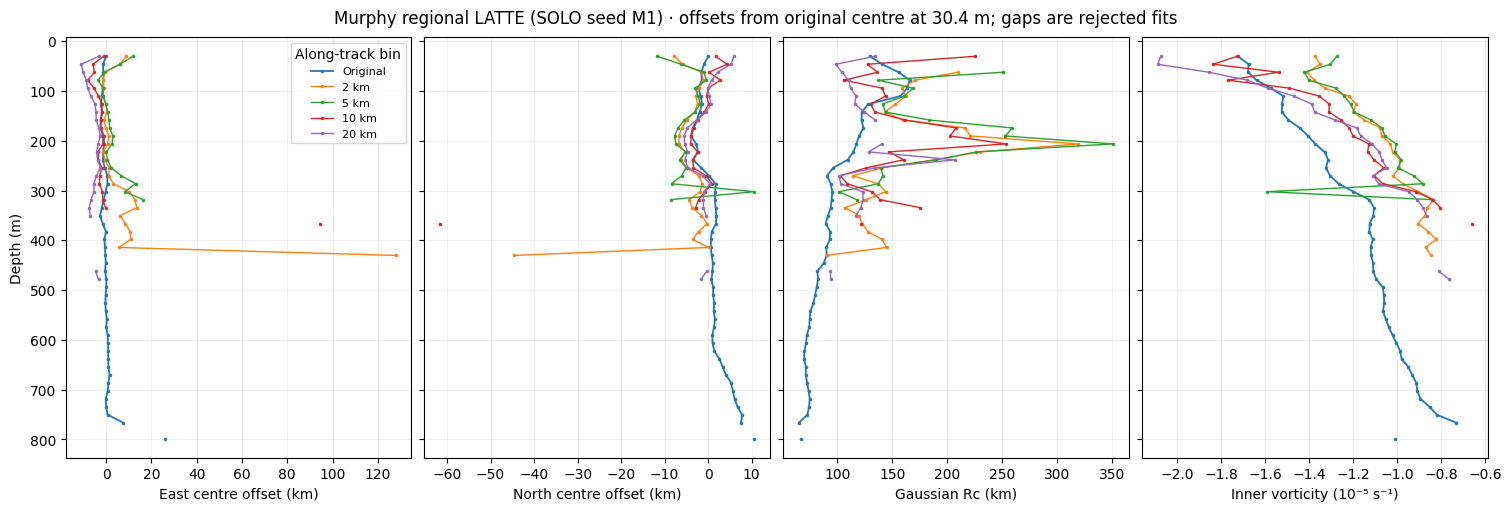

In [20]:
bin_data = data
bin_results = results
bin_coverage = coverage
bin_settings = FIT
bin_title = f"{EDDY} regional LATTE (SOLO seed {SOLO_TRANSECT})"

BIN_WIDTHS_KM = json.loads(CONFIG_PATH.read_text())["along_track_bin_km"]
if len(BIN_WIDTHS_KM) != len(set(BIN_WIDTHS_KM)):
    raise ValueError("along_track_bin_km must contain unique widths")
bin_fits = {"Original": bin_results}
bin_counts = [{"bin": "Original", "vectors": len(bin_data),
               "inner_depths": int(bin_results.inner_valid.sum()), "Rc_depths": int(bin_results.valid.sum())}]
for width_km in BIN_WIDTHS_KM:
    binned = esp.bin_solo_along_track(bin_data, width_km)
    fitted, _ = esp.fit_depths(binned, backend, "LATTE",
                               depth_levels=bin_coverage.index, **bin_settings)
    label = f"{width_km:g} km"
    bin_fits[label] = fitted
    bin_counts.append({"bin": label, "vectors": len(binned),
                       "inner_depths": int(fitted.inner_valid.sum()),
                       "Rc_depths": int(fitted.valid.sum())})
display(pd.DataFrame(bin_counts).set_index("bin"))
esp.plot_solo_binning_comparison(bin_fits, bin_title)
plt.show()
